## 1. Load data from csv file

In [ ]:
import pandas as pd
import numpy as np
 
df = pd.read_csv(
    "train.csv"
)
print(df.head())

   id keyword location                                               text  \
0   1     NaN      NaN  Our Deeds are the Reason of this #earthquake M...   
1   4     NaN      NaN             Forest fire near La Ronge Sask. Canada   
2   5     NaN      NaN  All residents asked to 'shelter in place' are ...   
3   6     NaN      NaN  13,000 people receive #wildfires evacuation or...   
4   7     NaN      NaN  Just got sent this photo from Ruby #Alaska as ...   

   target  
0       1  
1       1  
2       1  
3       1  
4       1  


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
# Shuffling and dropping unnecessary columns
df_shuffled = df.sample(frac=1, random_state=42)

# Dropping id, keyword and location columns as these columns consists of mostly nan values
# we will be using only text and target columns
df_shuffled.drop(["id", "keyword", "location"], axis=1, inplace=True)
df_shuffled.reset_index(inplace=True, drop=True)
print(df_shuffled.head())

                                                text  target
0  So you have a new weapon that can cause un-ima...       1
1  The f$&amp;@ing things I do for #GISHWHES Just...       0
2  DT @georgegalloway: RT @Galloway4Mayor: ÛÏThe...       1
3  Aftershock back to school kick off was great. ...       0
4  in response to trauma Children of Addicts deve...       0


In [3]:
test_df = df_shuffled.sample(frac=0.1, random_state=42)
train_df = df_shuffled.drop(test_df.index)
print(f"Using {len(train_df)} samples for training and {len(test_df)} for validation")

Using 6852 samples for training and 761 for validation


In [4]:
train_df = train_df.to_numpy()
test_df  = test_df.to_numpy()

## 2. Process data

### 2.1 Build vocab

In [15]:
# !pip -q install tokenizers

from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.trainers import WordLevelTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import Lowercase

vocab_limit = 20000   # max_tokens
min_freq = 3

hf_tokenizer = Tokenizer(WordLevel(unk_token="<unk>"))
hf_tokenizer.normalizer = Lowercase()
hf_tokenizer.pre_tokenizer = Whitespace()

trainer = WordLevelTrainer(
    vocab_size=vocab_limit,
    min_frequency=min_freq,
    special_tokens=["<pad>", "<s>", "</s>", "<unk>"]
)

# train_df: numpy array, mỗi row = [text, target]
hf_tokenizer.train_from_iterator((row[0] for row in train_df), trainer)

vocab = hf_tokenizer.get_vocab()
vocab_ordered = dict(sorted(vocab.items(), key=lambda x: x[1]))
vocab_size = len(vocab_ordered)

SPECIAL = {t: hf_tokenizer.token_to_id(t) for t in ["<pad>", "<s>", "</s>", "<unk>"]}

print("HF vocab_size =", vocab_size)
print("SPECIAL ids =", SPECIAL)


HF vocab_size = 4347
SPECIAL ids = {'<pad>': 0, '<s>': 1, '</s>': 2, '<unk>': 3}


### 2.2 Buid dataset

In [16]:
import torch
from torch.utils.data import Dataset

class Tweets_Dataset(Dataset):
    def __init__(self, data, max_len, tok, special):
        self.data = data          # numpy array: [text, target]
        self.max_len = max_len
        self.tok = tok
        self.pad = special["<pad>"]
        self.sos = special["<s>"]
        self.eos = special["</s>"]

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        text = self.data[idx][0]
        label = int(self.data[idx][1])

        ids = self.tok.encode(text).ids
        ids = [self.sos] + ids + [self.eos]  # add special tokens

        ids = ids[:self.max_len]             # truncate

        if len(ids) < self.max_len:          # pad right
            ids = ids + [self.pad] * (self.max_len - len(ids))

        return {
            "input_ids": torch.tensor(ids, dtype=torch.long),
            "labels": torch.tensor(label, dtype=torch.long),
        }


In [18]:
max_length = 200
train_data = Tweets_Dataset(train_df, max_length, hf_tokenizer, SPECIAL)
test_data  = Tweets_Dataset(test_df,  max_length, hf_tokenizer, SPECIAL)


### 2.3 Buid data loader

In [19]:
from torch.utils.data import DataLoader


batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

## 3. Model

In [ ]:
import torch.nn as nn

class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, dropout=0.0, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(in_features=embed_dim, out_features=ff_dim, bias=True),
            nn.ReLU(),
            nn.Linear(in_features=ff_dim, out_features=embed_dim, bias=True)
        )
        self.layernorm_1 = nn.LayerNorm(normalized_shape=embed_dim, eps=1e-6)
        self.layernorm_2 = nn.LayerNorm(normalized_shape=embed_dim, eps=1e-6)
        self.dropout_1 = nn.Dropout(p=dropout)
        self.dropout_2 = nn.Dropout(p=dropout)

    def forward(self, query, key, value):
        attn_output, _ = self.attn(query, key, value)
        attn_output = self.dropout_1(attn_output)
        out_1 = self.layernorm_1(query + attn_output)
        ffn_output = self.ffn(out_1)
        ffn_output = self.dropout_2(ffn_output)
        out_2 = self.layernorm_2(out_1 + ffn_output)
        return out_2


class TokenAndPositionEmbedding(nn.Module):
    def __init__(self, vocab_size, embed_dim, max_length, device):
        super().__init__()
        self.device = device
        self.word_emb = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim)
        self.pos_emb = nn.Embedding(num_embeddings=max_length, embedding_dim=embed_dim)

    def forward(self, x):
        N, seq_len = x.size()
        positions = torch.arange(0, seq_len).expand(N, seq_len).to(self.device)
        output1 = self.word_emb(x)
        output2 = self.pos_emb(positions)
        output = output1 + output2
        return output


class TransformerTextCls(nn.Module):
    def __init__(self, vocab_size, max_length, embed_dim, num_heads, ff_dim, dropout, device):
        super().__init__()
        self.embd_layer = TokenAndPositionEmbedding(vocab_size, embed_dim, max_length, device)
        self.transformer_layer = TransformerBlock(embed_dim, num_heads, ff_dim, dropout)
        self.pooling = nn.AvgPool1d(kernel_size=max_length)
        self.fc1 = nn.Linear(in_features=embed_dim, out_features=20)
        self.fc2 = nn.Linear(in_features=20, out_features=2)
        self.dropout = nn.Dropout(p=dropout)
        self.relu = nn.ReLU()
    def forward(self, x):
        output = self.embd_layer(x)
        output = self.transformer_layer(output, output, output)
        output = self.pooling(output.permute(0,2,1)).squeeze()
        output = self.dropout(output)
        output = self.fc1(output)
        output = self.dropout(output)
        output = self.fc2(output)
        return output


In [21]:
embed_dim = 32
num_heads = 2
ff_dim = 32
dropout = 0.1
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = TransformerTextCls(vocab_size, max_length, embed_dim, num_heads, ff_dim, dropout, device)

## 4. Training

### 4.1 Eval function

In [22]:
def evaluate(model, test_loader, criterion, device):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in test_loader:
            inputs, labels = batch['input_ids'].to(device), batch['labels'].to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            test_loss += loss.item()
            correct +=(predicted == labels).sum().item()

    test_loss = test_loss / len(test_loader)
    accuracy = 100* correct / total

    return test_loss, accuracy

### 4.2 Train model

In [23]:
max_epoch = 40
LR = 0.001
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [24]:
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

model.to(device)
for epoch in range(max_epoch):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0
    for batch in train_loader:
        inputs, labels = batch['input_ids'].to(device), batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        running_correct += (predicted == labels).sum().item()

        loss.backward()
        optimizer.step()

    epoch_loss =  running_loss / len(train_loader)
    epoch_accuracy = 100* running_correct / total
    test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

    print(f"Epoch [{epoch + 1}/{max_epoch}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [1/40], Loss: 0.6864, Accuracy: 56.22%, Test Loss: 0.6909, Test Accuracy: 54.27%
Epoch [2/40], Loss: 0.6793, Accuracy: 57.43%, Test Loss: 0.6769, Test Accuracy: 56.64%
Epoch [3/40], Loss: 0.6545, Accuracy: 60.95%, Test Loss: 0.6266, Test Accuracy: 64.65%
Epoch [4/40], Loss: 0.5980, Accuracy: 68.40%, Test Loss: 0.5782, Test Accuracy: 70.43%
Epoch [5/40], Loss: 0.5462, Accuracy: 72.88%, Test Loss: 0.5511, Test Accuracy: 72.54%
Epoch [6/40], Loss: 0.5162, Accuracy: 74.87%, Test Loss: 0.5360, Test Accuracy: 74.38%
Epoch [7/40], Loss: 0.4868, Accuracy: 76.75%, Test Loss: 0.7334, Test Accuracy: 67.15%
Epoch [8/40], Loss: 0.4775, Accuracy: 77.54%, Test Loss: 0.5342, Test Accuracy: 75.82%
Epoch [9/40], Loss: 0.4623, Accuracy: 78.37%, Test Loss: 0.5535, Test Accuracy: 73.19%
Epoch [10/40], Loss: 0.4449, Accuracy: 80.25%, Test Loss: 0.5335, Test Accuracy: 75.56%
Epoch [11/40], Loss: 0.4354, Accuracy: 80.43%, Test Loss: 0.5398, Test Accuracy: 76.48%
Epoch [12/40], Loss: 0.4270, Accuracy: 80

### 4.3 Plot the result

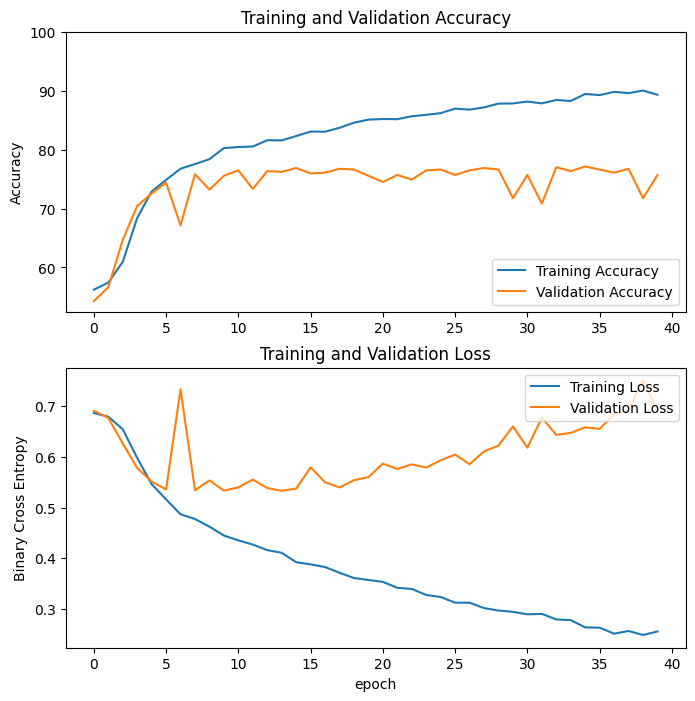

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(test_accuracies, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),100])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(train_losses, label='Training Loss')
plt.plot(test_losses, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Binary Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()